# Evaluate CatBoost before and after tuning
All metrics are on the test set. The positive class is `transported`.

## Metric functions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

CLASS_NAMES = ["not transported", "transported"]
BEFORE_COLOR = "#eb6834"
AFTER_COLOR = "#2a78d6"
GUESS_COLOR = "#898781"


def get_confusion_matrix(model, X, y):
    predictions = model.predict(X).astype(int).ravel()
    return confusion_matrix(y, predictions, labels=model.classes_)


def calculate_metrics(matrix):
    tn, fp, fn, tp = matrix.ravel()

    accuracy = (tp + tn) / matrix.sum()
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)

    return {
        "accuracy": accuracy,
        "error_rate": 1 - accuracy,
        "precision": precision,
        "recall (sensitivity)": recall,
        "specificity": tn / (tn + fp),
        "f1": 2 * precision * recall / (precision + recall),
    }


def plot_confusion_matrix(matrix, title):
    display = ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES)
    display.plot(cmap="Blues", colorbar=False)
    plt.title(title)
    plt.show()


def plot_roc(curves, title):
    """curves: list of (label, model, X, y, color, linestyle). Returns {label: AUC}."""
    fig, ax = plt.subplots(figsize=(6, 6))
    auc_scores = {}
    for label, model, X, y, color, linestyle in curves:
        # Column 1 of predict_proba is the positive class (transported)
        scores = model.predict_proba(X)[:, 1]
        fpr, tpr, _ = roc_curve(y, scores)
        auc_scores[label] = roc_auc_score(y, scores)
        ax.plot(fpr, tpr, color=color, linestyle=linestyle, linewidth=2,
                label=f"{label} (AUC = {auc_scores[label]:.4f})")

    ax.plot([0, 1], [0, 1], color=GUESS_COLOR, linewidth=1, linestyle="--",
            label="random guess (AUC = 0.5)")
    ax.set_title(title)
    ax.set_xlabel("False positive rate (1 - specificity)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect("equal")
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False)
    plt.show()
    return auc_scores

## 1. Before tuning

In [2]:
%run train_baseline.ipynb

model_before, X_test_before, y_test_before = model, X_test_cb, y_test

Selected Numeric Features: ['roomservice', 'spa', 'vrdeck']
Selected Categorical Features: ['cryosleep']
['roomservice', 'spa', 'vrdeck', 'cryosleep']
(5215, 4) (1739, 4) (1739, 4)
(5215,) (1739,) (1739,)
0:	test: 0.8017422	best: 0.8017422 (0)	total: 57.6ms	remaining: 1m 55s
200:	test: 0.8111809	best: 0.8118661 (144)	total: 247ms	remaining: 2.21s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.8118660614
bestIteration = 144

Shrink model to first 145 iterations.
train      acc=0.7749  f1=0.7862  auc=0.8306
validation acc=0.7596  f1=0.7726  auc=0.8119
test       acc=0.7734  f1=0.7826  auc=0.8197


### Confusion matrix

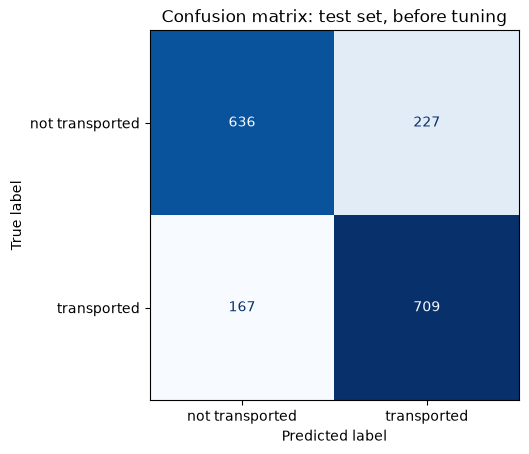

In [3]:
matrix_before = get_confusion_matrix(model_before, X_test_before, y_test_before)
plot_confusion_matrix(matrix_before, "Confusion matrix: test set, before tuning")

### Metrics

In [4]:
metrics_before = calculate_metrics(matrix_before)
pd.Series(metrics_before, name="before tuning").round(4).to_frame()

,before tuning
accuracy,0.7734
error_rate,0.2266
precision,0.7575
recall (sensitivity),0.8094
specificity,0.7370
f1,0.7826


### ROC curve

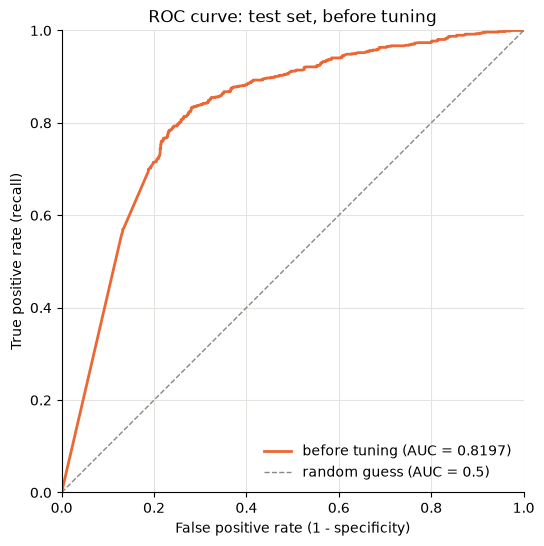

In [5]:
auc_before = plot_roc(
    [("before tuning", model_before, X_test_before, y_test_before, BEFORE_COLOR, "-")],
    "ROC curve: test set, before tuning",
)["before tuning"]

## 2. After tuning

In [6]:
%run train.ipynb

model_after, X_test_after, y_test_after = model, X_test_cb, y_test

18 features: ['homeplanet', 'cryosleep', 'destination', 'vip', 'deck', 'side', 'age', 'group_size', 'solo', 'cabin_num', 'total_spend', 'no_spend', 'log_roomservice', 'log_foodcourt', 'log_shoppingmall', 'log_spa', 'log_vrdeck', 'log_total_spend']
(5215, 18) (1739, 18) (1739, 18)
(5215,) (1739,) (1739,)
fold 0: acc=0.8181  trees=1177
fold 1: acc=0.8095  trees=1097
fold 2: acc=0.8246  trees=1127
fold 3: acc=0.8124  trees=1397
fold 4: acc=0.8129  trees=874
CV accuracy = 0.8155 ± 0.0053  | trees for final model: 1127
0:	learn: 0.7626079	test: 0.7492812	best: 0.7492812 (0)	total: 3.71ms	remaining: 11.1s
200:	learn: 0.8222435	test: 0.7958597	best: 0.8010351 (154)	total: 732ms	remaining: 10.2s
400:	learn: 0.8433365	test: 0.8004600	best: 0.8021852 (338)	total: 1.44s	remaining: 9.36s
600:	learn: 0.8661553	test: 0.8027602	best: 0.8067855 (550)	total: 2.18s	remaining: 8.72s
800:	learn: 0.8832215	test: 0.8056354	best: 0.8073606 (719)	total: 2.96s	remaining: 8.12s
Stopped by overfitting detector  

### Confusion matrix

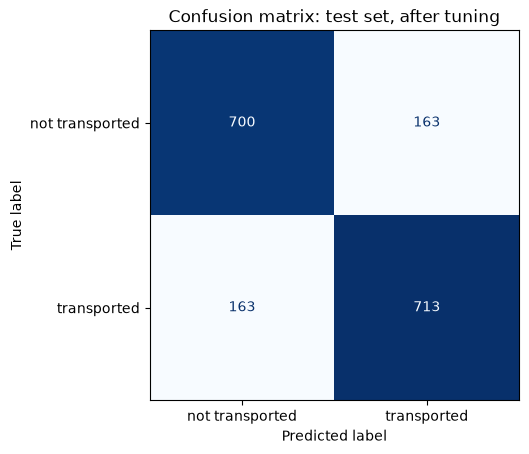

In [7]:
matrix_after = get_confusion_matrix(model_after, X_test_after, y_test_after)
plot_confusion_matrix(matrix_after, "Confusion matrix: test set, after tuning")

### Metrics

In [8]:
metrics_after = calculate_metrics(matrix_after)
pd.Series(metrics_after, name="after tuning").round(4).to_frame()

,after tuning
accuracy,0.8125
error_rate,0.1875
precision,0.8139
recall (sensitivity),0.8139
specificity,0.8111
f1,0.8139


### ROC curve

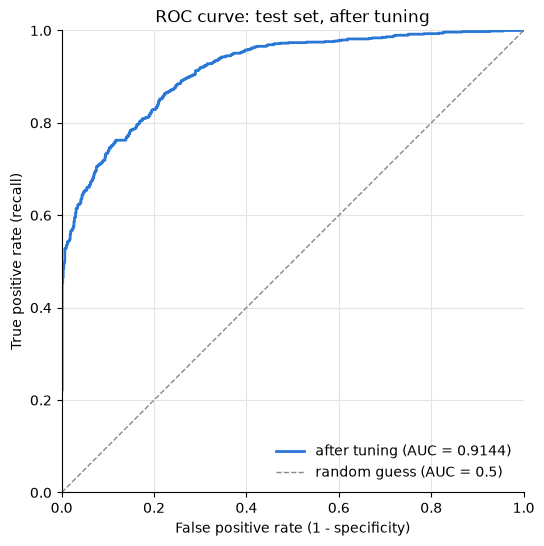

In [9]:
auc_after = plot_roc(
    [("after tuning", model_after, X_test_after, y_test_after, AFTER_COLOR, "-")],
    "ROC curve: test set, after tuning",
)["after tuning"]

## 3. Comparison
Both models must be scored on the same test passengers, otherwise the comparison is not fair.

In [10]:
same_test_set = (y_test_before.index.equals(y_test_after.index)
                 and y_test_before.equals(y_test_after))
if not same_test_set:
    raise ValueError("y_test_before and y_test_after are not the same test set")
print(f"Same test set: {same_test_set} ({len(y_test_after)} rows)")

Same test set: True (1739 rows)


### Metrics and AUC

In [11]:
comparison = pd.DataFrame({
    "before tuning": {**metrics_before, "auc": auc_before},
    "after tuning": {**metrics_after, "auc": auc_after},
})
comparison["change"] = comparison["after tuning"] - comparison["before tuning"]
comparison.round(4)

,before tuning,after tuning,change
accuracy,0.7734,0.8125,0.0391
error_rate,0.2266,0.1875,-0.0391
precision,0.7575,0.8139,0.0564
recall (sensitivity),0.8094,0.8139,0.0046
specificity,0.7370,0.8111,0.0742
f1,0.7826,0.8139,0.0314
auc,0.8197,0.9144,0.0947


### ROC curves

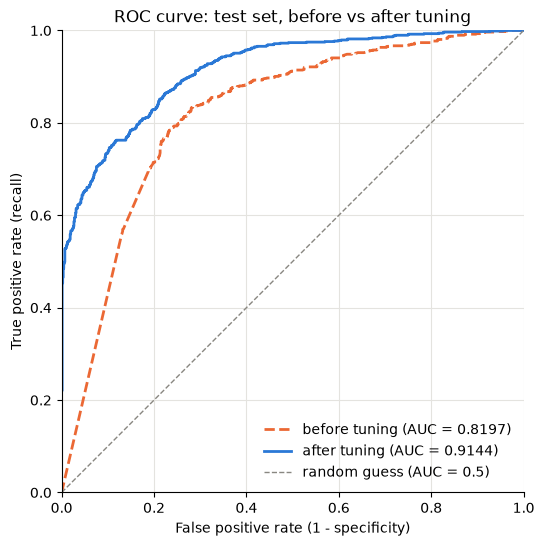

In [12]:
plot_roc(
    [
        ("before tuning", model_before, X_test_before, y_test_before, BEFORE_COLOR, "--"),
        ("after tuning", model_after, X_test_after, y_test_after, AFTER_COLOR, "-"),
    ],
    "ROC curve: test set, before vs after tuning",
);